# Proyecto no supervisado: delitos en Bolivia, por departamento, ciudad y zona (v5)

**Flujo:** medios (sitemaps + YouTube) → extracción → ubicación (departamento → ciudad → zona) → clasificación (delito, hora) → CSV → modelos no supervisados.

**Cómo está organizado el análisis (y por qué):**
- **Nacional / departamento:** todo hecho con departamento conocido. Sirve para texto (LDA, UMAP, t-SNE), comparación de departamentos y patrones por hora/día.
- **Ciudad:** hecho con ciudad conocida. Mapas por ciudad y comparaciones entre ciudades.
- **Zona:** hecho con barrio/zona **y coordenadas**. Solo estos sirven para DBSCAN/HDBSCAN/OPTICS y clusters de zonas, y se analizan **ciudad por ciudad** (nunca mezclando ciudades en un mismo mapa de densidad).

**Reglas para no ser bloqueado y hacerlo bien:** respeta `robots.txt` y `Crawl-delay`, pausas de 3–6 s, caché en disco (nunca se pide dos veces la misma URL), freno automático ante 403/429, y se omiten los sitios que declaran `ai-train=no` (se puede cambiar con `RESPETAR_CONTENT_SIGNAL`). Colab comparte IPs: si te bloquean, corre desde tu PC. No publiques nombres de víctimas en el dashboard.

**Sesgo de cobertura:** lo que se mide son hechos *que salen en medios*, no el crimen real. Los medios cubren más lo cercano a sus sedes y a las ciudades grandes. Dilo en el informe.

In [1]:
!pip -q install geopy unidecode trafilatura requests-cache feedparser umap-learn folium

## 1. Configuración
La clave de YouTube se lee de **Secretos de Colab** (icono de llave → nombre `YOUTUBE_API_KEY`). Nunca la pegues en el código.

In [2]:
import re, os, time, json, random, gzip, collections, html as _html, urllib.robotparser
import xml.etree.ElementTree as ET
from urllib.parse import urlparse, urljoin
import requests, requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
import pandas as pd, numpy as np
from unidecode import unidecode
import trafilatura

CONTACTO = "tu_correo@gmail.com"      # <-- CAMBIA ESTO (mejor un correo personal que revises)
USER_AGENT = f"ProyectoUniversitarioML/5.0 (investigacion academica; contacto: {CONTACTO})"
PAUSA_MIN, PAUSA_MAX = 3.0, 6.0       # segundos entre peticiones REALES (las de caché no esperan)
MAX_ERRORES_SEGUIDOS = 3              # 403/429 seguidos -> el cliente se detiene
RESPETAR_CONTENT_SIGNAL = True        # omite sitios cuyo robots.txt declara ai-train=no
CSV_EVENTOS = "eventos_bolivia_v5.csv"
CSV_ANTERIOR = "eventos_lapaz_v3.csv"  # si existe, se importa (y reclasifica) la primera vez
CARPETA_GAZ = "gazetteer"
CARPETA_SALIDA = "salida"

try:
    from google.colab import userdata
    YOUTUBE_API_KEY = userdata.get("YOUTUBE_API_KEY")
except Exception:
    YOUTUBE_API_KEY = os.environ.get("YOUTUBE_API_KEY", "")

def norm(t): return unidecode(t if isinstance(t, str) else "").lower()

# gravedad relativa de cada tipo de delito (para el índice de gravedad)
PESO = {"Homicidio / Asesinato": 5, "Violencia sexual": 4, "Agresión Física y Lesiones": 3, "Robo Agravado / Asalto": 3,
        "Robo de Vehículos y Autopartes": 2, "Hurto / Descuidismo": 1, "Estafa y Engaño": 1, "Narcotráfico / Drogas": 1}
EXCLUIR = ["No especificado", "Judicial / Político", "Conflicto social / Bloqueos"]

## 2. Geografía de Bolivia: departamentos y ciudades
- `CIUDADES`: centro **aproximado** de cada ciudad y un radio de validación (grados). Es para el **nivel ciudad**; **no** sirve para ubicar zonas. Verifica los puntos en el mapa de la sección 9.
- `POBLACION`: Censo 2012 (aprox.). **Actualiza con el Censo 2024 del INE** antes de calcular tasas por 100.000 habitantes.
- Si falta una ciudad importante para ti, agrégala en `CIUDADES`: `"Nombre": ("Departamento", lat, lon, radio_en_grados)`.

In [3]:
# ciudad -> (departamento, lat, lon, radio de validación en grados)  | centros aproximados
CIUDADES = {
    "La Paz": ("La Paz", -16.500, -68.150, 0.15), "El Alto": ("La Paz", -16.505, -68.185, 0.15),
    "Copacabana": ("La Paz", -16.167, -69.083, 0.05), "Desaguadero": ("La Paz", -16.567, -69.033, 0.04),
    "Caranavi": ("La Paz", -15.833, -67.567, 0.05),
    "Santa Cruz": ("Santa Cruz", -17.784, -63.182, 0.20), "Montero": ("Santa Cruz", -17.339, -63.251, 0.08),
    "Warnes": ("Santa Cruz", -17.515, -63.168, 0.08), "La Guardia": ("Santa Cruz", -17.897, -63.322, 0.06),
    "Cotoca": ("Santa Cruz", -17.750, -63.030, 0.05), "Camiri": ("Santa Cruz", -20.050, -63.517, 0.06),
    "Cochabamba": ("Cochabamba", -17.394, -66.157, 0.15), "Quillacollo": ("Cochabamba", -17.398, -66.278, 0.07),
    "Sacaba": ("Cochabamba", -17.400, -66.040, 0.07), "Colcapirhua": ("Cochabamba", -17.388, -66.225, 0.05),
    "Tiquipaya": ("Cochabamba", -17.338, -66.217, 0.05), "Villa Tunari": ("Cochabamba", -16.975, -65.417, 0.06),
    "Sucre": ("Chuquisaca", -19.020, -65.262, 0.12),
    "Oruro": ("Oruro", -17.965, -67.106, 0.12),
    "Potosí": ("Potosí", -19.584, -65.753, 0.10), "Uyuni": ("Potosí", -20.463, -66.826, 0.05),
    "Llallagua": ("Potosí", -18.417, -66.617, 0.05), "Tupiza": ("Potosí", -21.443, -65.717, 0.05),
    "Villazón": ("Potosí", -22.087, -65.595, 0.05),
    "Tarija": ("Tarija", -21.535, -64.730, 0.10), "Yacuiba": ("Tarija", -22.017, -63.683, 0.08),
    "Villamontes": ("Tarija", -21.267, -63.483, 0.06), "Bermejo": ("Tarija", -22.733, -64.333, 0.05),
    "Trinidad": ("Beni", -14.833, -64.900, 0.08), "Riberalta": ("Beni", -11.000, -66.070, 0.06),
    "Guayaramerín": ("Beni", -10.817, -65.350, 0.05),
    "Cobija": ("Pando", -11.027, -68.769, 0.06),
}
DEPARTAMENTOS = {"La Paz": "La Paz", "Santa Cruz": "Santa Cruz de la Sierra", "Cochabamba": "Cochabamba", "Chuquisaca": "Sucre", "Oruro": "Oruro",
                 "Potosí": "Potosí", "Tarija": "Tarija", "Beni": "Trinidad", "Pando": "Cobija"}        # departamento -> capital
POBLACION = {"La Paz": 2706351, "Santa Cruz": 2655084, "Cochabamba": 1758143, "Potosí": 828093, "Chuquisaca": 581347,
             "Oruro": 494178, "Tarija": 482196, "Beni": 421196, "Pando": 110436}      # Censo 2012 (aprox.) -> ACTUALIZA con el Censo 2024

# patrones de ciudad (con guardas contra homónimos: Av. Mariscal Santa Cruz, Antonio José de Sucre, Huayna Potosí, "el alto mando"...)
_PAT_CIUDAD = {
    "La Paz": r"\bla paz\b",
    "El Alto": r"\bel alto\b(?! mando| comando| riesgo| nivel| costo| precio| mandatario)",
    "Santa Cruz": r"(?<!mariscal )(?<!andres de )\bsanta cruz\b",
    "Sucre": r"(?<!mariscal )(?<!jose de )(?<!avenida )(?<!av\. )(?<!calle )\bsucre\b",
    "Potosí": r"(?<!huayna )\bpotosi\b",
    "Trinidad": r"\btrinidad,? beni\b|\bciudad de trinidad\b|\ben trinidad\b",
}
_RX_CIUDAD = {c: re.compile(_PAT_CIUDAD.get(c, rf"\b{re.escape(norm(c))}\b")) for c in CIUDADES}
_PAT_DEPTO = {"Chuquisaca": r"\bchuquisaca\b", "Beni": r"\bbeni\b", "Pando": r"\bpando\b",
              "Cochabamba": r"\bchapare\b|\btropico de cochabamba\b", "La Paz": r"\byungas\b|\baltiplano paceno\b",
              "Santa Cruz": r"\bchiquitania\b", "Tarija": r"\bchaco tarijeno\b"}
_RX_DEPTO = {d: re.compile(p) for d, p in _PAT_DEPTO.items()}
_EXTRANJERO = re.compile(r"\b(chile|peru|argentina|brasil|colombia|mexico|ecuador|paraguay|venezuela|espana|estados unidos|eeuu|uruguay|panama|cuba|haiti|honduras|guatemala|nicaragua|rusia|ucrania|israel|gaza|china|iquique|tacna|arica|lima|buenos aires|sao paulo)\b")

def _primera(rxs, t):
    hall = [(m.start(), k) for k, rx in rxs.items() for m in [rx.search(t)] if m]
    return min(hall)[1] if hall else None

def detectar_ubicacion(titulo, cuerpo=""):
    """(ciudad, departamento). El título manda sobre el cuerpo; si no hay ciudad se intenta el departamento."""
    tt, tb = norm(titulo), norm((cuerpo or "")[:600])
    ciudad = _primera(_RX_CIUDAD, tt) or _primera(_RX_CIUDAD, tb)
    if ciudad: return ciudad, CIUDADES[ciudad][0]
    return None, (_primera(_RX_DEPTO, tt) or _primera(_RX_DEPTO, tb))

def es_extranjero(titulo, cuerpo=""):
    ciudad, depto = detectar_ubicacion(titulo, cuerpo)
    return bool(_EXTRANJERO.search(norm(titulo))) and not ciudad and not depto

def coordenada_valida(ciudad, lat, lon):
    if lat is None or lon is None or ciudad not in CIUDADES: return False
    _, la, lo, h = CIUDADES[ciudad]
    return abs(lat - la) <= h and abs(lon - lo) <= h

## 3. Zonas: tu diccionario de La Paz y El Alto + registro para todas las ciudades
Abajo va **tu diccionario y tus coordenadas manuales** (sin cambios, salvo la corrección de "12 de Octubre", que coincidía con fechas). Se cargan en un **registro por ciudad** (`ZONAS[ciudad][zona]`). Para las demás ciudades hay dos caminos:
1. **Manual (más preciso):** agrega zonas en `NUEVAS_ZONAS` con alias y coordenadas (clic derecho en Google Maps → copiar `lat, lon`).
2. **Gazetteer de OpenStreetMap (automático, sección 8):** descarga los barrios que OSM tiene para esa ciudad (una consulta por ciudad, con caché). Su calidad varía por ciudad: **revisa el mapa** antes de confiar.

In [4]:
import re

# Diccionario organizado de zonas y avenidas neurálgicas (La Paz y El Alto)
PATRONES_ZONAS = {
    # --- MACRODISTRITO CENTRO (LA PAZ) ---
    "Pérez Velasco": ["perez velasco", "pérez velasco", "plaza perez", "pasarela perez"],
    "San Francisco": ["san francisco", "plaza san francisco", "sagarnaga", "calle sagárnaga"],
    "Plaza Murillo": ["plaza murillo", "calle comercio", "calle ingavi", "calle socabaya", "calle ballivian"],
    "El Prado": ["el prado", "paseo del prado", "avenida 16 de julio", "plaza del estudiante"],
    "San Pedro": ["san pedro", "plaza sucre", "plaza san pedro", "calle colombia", "panóptico de san pedro"],
    "Camacho": ["avenida camacho", "mercado camacho", "calle bueno", "santa barbara"],
    "Miraflores": ["miraflores", "plaza villarroel", "estadio hernando siles", "avenida saavedra",
                   "plaza triangular", "hospital de clinicas", "avenida brasil", "puente de las americas"],
    "San Jorge": ["san jorge", "avenida arce", "plaza el condor"],

    # --- MACRODISTRITO COTAHUMA ---
    "Sopocachi": ["sopocachi", "plaza abaroa", "plaza españa", "calle 20 de octubre",
                  "avenida 6 de agosto", "belisario salinas", "plaza monticulo", "montículo"],
    "Tembladerani": ["tembladerani", "cancha de tembladerani", "jaimes freyre"],
    "Bajo Llojeta": ["bajo llojeta", "llojeta", "mario mercado"],
    "Pasankeri": ["pasankeri", "curva de holguin"],
    "Tacagua": ["tacagua", "faro murillo"],
    "Alpacoma": ["alpacoma", "relleno sanitario alpacoma"],

    # --- MACRODISTRITO MAX PAREDES ---
    "Garita de Lima": ["garita de lima", "plaza garita de lima", "calle tumusla", "tumusla"],
    "Gran Poder": ["gran poder", "calle illampu", "calle vicente ochoa", "calle gallardo"],
    "Avenida Buenos Aires": ["avenida buenos aires", "av. buenos aires", "buenos aires y max paredes"],
    "El Tejar": ["el tejar", "calle collasuyo", "cementerio general"],
    "Villa Victoria": ["villa victoria", "plaza huallparrimachi"],
    "Chijini": ["chijini", "plaza marcelo quiroga santa cruz"],
    "Munaypata": ["munaypata", "autopista la paz el alto", "puente autopista"],
    "Pura Pura": ["pura pura", "bosquecillo de pura pura"],

    # --- MACRODISTRITO PERIFÉRICA ---
    "Villa Fátima": ["villa fátima", "villa fatima", "plaza del maestro", "mercado villa fatima", "terminal minasa"],
    "Achachicala": ["achachicala", "carril de subida", "avenida ramiro castillo"],
    "Vino Tinto": ["vino tinto", "puente minasa"],
    "Rosasani": ["rosasani", "plaza de rosasani"],

    # --- MACRODISTRITO SAN ANTONIO ---
    "Villa Copacabana": ["villa copacabana", "hospital san gabriel", "avenida circunvalacion"],
    "Villa San Antonio": ["villa san antonio", "san antonio alto", "san antonio bajo", "plaza libertad"],
    "Pampahasi": ["pampahasi", "alto pampahasi", "bajo pampahasi"],
    "Kupini": ["kupini", "callapa"],

    # --- MACRODISTRITO SUR Y MALLASA ---
    "Obrajes": ["obrajes", "calle 17 de obrajes", "calle 8 de obrajes", "calle 2 de obrajes", "avenida hernando siles"],
    "Bella Vista": ["bella vista", "plaza de bella vista"],
    "Següencoma": ["seguencoma", "següencoma", "bajo següencoma"],
    "Calacoto": ["calacoto", "calle 21 de calacoto", "calle 8 de calacoto", "plaza humboldt", "avenida ballivian"],
    "San Miguel": ["san miguel", "avenida montenegro", "calle pancara"],
    "La Florida": ["la florida", "puente amor de dios"],
    "Los Pinos": ["los pinos", "plaza los pinos"],
    "Cota Cota": ["cota cota", "calle 28 de cota cota", "campus cota cota", "laguna de cota cota"],
    "Chasquipampa": ["chasquipampa", "calle 50 de chasquipampa", "calle 42 de chasquipampa"],
    "Achumani": ["achumani", "calle 22 de achumani", "avenida garcia lanza", "complejo the strongest"],
    "Irpavi": ["irpavi", "irpavi 2", "megacenter", "avenida ovando"],
    "Mallasa": ["mallasa", "valle de la luna"],

    # --- CIUDAD DE EL ALTO ---
    "La Ceja": ["la ceja", "ceja de el alto", "ceja el alto", "calle 1 de la ceja", "pasarela del arquitecto"],
    "Villa Dolores": ["villa dolores", "plaza juana azurduy"],
    "12 de Octubre": ["12 de octubre", "zona 12 de octubre", "calle jorge carrasco", "calle raul salmón"],
    "Ciudad Satélite": ["ciudad satelite", "ciudad satélite", "plaza del obelisco el alto"],
    "Río Seco": ["rio seco", "río seco", "ex tranca rio seco", "puente rio seco"],
    "Senkata": ["senkata", "ex tranca senkata", "planta de senkata"],
    "Ballivián": ["ballivian el alto", "plaza ballivian", "plaza ballivián"],
    "Cruce Villa Adela": ["cruce villa adela", "villa adela"],
    "Villa Esperanza": ["villa esperanza", "upea"],

    # --- TERMINALES E HITOS DE CONEXIÓN ---
    "Terminal de Buses La Paz": ["terminal de buses", "terminal de la paz", "plaza antogafasta"],
    "Terminal Minasa": ["terminal minasa"],
    "Terminal Interprovincial": ["terminal interprovincial de el alto"],
    "Tranca de Urujara": ["urujara", "tranca de urujara"]
}

# Zonas asignadas al Municipio de El Alto
ZONAS_EL_ALTO = {
    "La Ceja", "Villa Dolores", "12 de Octubre", "Ciudad Satélite",
    "Río Seco", "Senkata", "Ballivián", "Cruce Villa Adela",
    "Villa Esperanza", "Terminal Interprovincial"
}
PATRONES_ZONAS["12 de Octubre"] = ["zona 12 de octubre", "urbanizacion 12 de octubre", "calle jorge carrasco", "calle raul salmon"]   # corrección: antes coincidía con la fecha "el 12 de octubre"

In [5]:
COORDS_MANUALES = {
    # --- MACRODISTRITO CENTRO (LA PAZ) ---
    "Pérez Velasco": (-16.4954, -68.1368),
    "San Francisco": (-16.4961, -68.1371),
    "Plaza Murillo": (-16.4958, -68.1336),
    "El Prado": (-16.5015, -68.1315),
    "San Pedro": (-16.5018, -68.1357),
    "Camacho": (-16.4988, -68.1325),
    "Miraflores": (-16.4994, -68.1228),
    "San Jorge": (-16.5125, -68.1220),

    # --- MACRODISTRITO COTAHUMA ---
    "Sopocachi": (-16.5108, -68.1275),
    "Tembladerani": (-16.5078, -68.1462),
    "Bajo Llojeta": (-16.5250, -68.1405),
    "Pasankeri": (-16.5052, -68.1580),
    "Tacagua": (-16.4980, -68.1565),
    "Alpacoma": (-16.5360, -68.1510),

    # --- MACRODISTRITO MAX PAREDES ---
    "Garita de Lima": (-16.4938, -68.1435),
    "Gran Poder": (-16.4975, -68.1415),
    "Avenida Buenos Aires": (-16.4990, -68.1480),
    "El Tejar": (-16.4915, -68.1495),
    "Villa Victoria": (-16.4865, -68.1520),
    "Chijini": (-16.4970, -68.1440),
    "Munaypata": (-16.4880, -68.1595),
    "Pura Pura": (-16.4815, -68.1530),

    # --- MACRODISTRITO PERIFÉRICA ---
    "Villa Fátima": (-16.4820, -68.1130),
    "Achachicala": (-16.4670, -68.1380),
    "Vino Tinto": (-16.4800, -68.1310),
    "Rosasani": (-16.4780, -68.1210),

    # --- MACRODISTRITO SAN ANTONIO ---
    "Villa Copacabana": (-16.4950, -68.1070),
    "Villa San Antonio": (-16.5020, -68.1050),
    "Pampahasi": (-16.5050, -68.0890),
    "Kupini": (-16.5130, -68.0950),

    # --- MACRODISTRITO SUR Y MALLASA ---
    "Obrajes": (-16.5265, -68.1120),
    "Bella Vista": (-16.5330, -68.1005),
    "Següencoma": (-16.5310, -68.1080),
    "Calacoto": (-16.5395, -68.0865),
    "San Miguel": (-16.5410, -68.0825),
    "La Florida": (-16.5385, -68.0950),
    "Los Pinos": (-16.5440, -68.0770),
    "Cota Cota": (-16.5380, -68.0690),
    "Chasquipampa": (-16.5450, -68.0580),
    "Achumani": (-16.5320, -68.0650),
    "Irpavi": (-16.5270, -68.0870),
    "Mallasa": (-16.5680, -68.0760),

    # --- CIUDAD DE EL ALTO ---
    "La Ceja": (-16.5075, -68.1630),
    "Villa Dolores": (-16.5160, -68.1620),
    "12 de Octubre": (-16.5110, -68.1645),
    "Ciudad Satélite": (-16.5240, -68.1550),
    "Río Seco": (-16.4920, -68.2120),
    "Senkata": (-16.5650, -68.1960),
    "Ballivián": (-16.4970, -68.1790),
    "Cruce Villa Adela": (-16.5320, -68.1880),
    "Villa Esperanza": (-16.4900, -68.1940),

    # --- TERMINALES E INFRAESTRUCTURA ---
    "Terminal de Buses La Paz": (-16.4905, -68.1405),
    "Terminal Minasa": (-16.4785, -68.1085),
    "Terminal Interprovincial": (-16.4950, -68.2050),
    "Tranca de Urujara": (-16.4550, -68.0860)
}

In [6]:
ZONAS = collections.defaultdict(dict)    # ZONAS[ciudad][zona] = {"alias": [...], "coords": (lat, lon) | None, "origen": "manual" | "osm"}

def agregar_zona(ciudad, zona, alias, coords=None, origen="manual"):
    assert ciudad in CIUDADES, f"Ciudad desconocida: {ciudad}"
    if coords and not coordenada_valida(ciudad, *coords):
        print(f"  ! {zona} ({ciudad}): coordenadas fuera del área de la ciudad {coords}"); coords = None
    ZONAS[ciudad][zona] = {"alias": list(alias), "coords": tuple(coords) if coords else None, "origen": origen}

for _z, _als in PATRONES_ZONAS.items():
    agregar_zona("El Alto" if _z in ZONAS_EL_ALTO else "La Paz", _z, _als, COORDS_MANUALES.get(_z))

NUEVAS_ZONAS = [
    # {"ciudad": "Santa Cruz", "zona": "Plan 3000", "alias": ["plan 3000", "plan tres mil"], "coords": (-17.0000, -63.0000)},   # <- ejemplo: reemplaza coords
]
for _n in NUEVAS_ZONAS: agregar_zona(_n["ciudad"], _n["zona"], _n["alias"], _n.get("coords"))

_RX_ZONAS = {}
def reconstruir_alias():
    """Recompila los alias de zonas (llámala después de agregar zonas o cargar un gazetteer)."""
    global _RX_ZONAS
    _RX_ZONAS = {}
    for c, zs in ZONAS.items():
        lst = sorted([(norm(a), z, d["origen"]) for z, d in zs.items() for a in d["alias"]], key=lambda x: -len(x[0]))
        _RX_ZONAS[c] = [(re.compile(rf"\b{re.escape(a)}\b"), z, o) for a, z, o in lst]
reconstruir_alias()

def _grupo(ciudad):   # La Paz y El Alto son una conurbación: sus zonas se buscan juntas
    return ["La Paz", "El Alto"] if ciudad in ("La Paz", "El Alto") else [ciudad]

def detectar_zonas(texto, ciudad_texto=None):
    """{(ciudad, zona): n} y posiciones. Con ciudad explícita se usan todas las zonas de esa ciudad; sin ciudad, solo las manuales."""
    t = norm(texto); cnt, pos = {}, {}
    for c in (_grupo(ciudad_texto) if ciudad_texto else list(_RX_ZONAS)):
        for rx, z, o in _RX_ZONAS.get(c, []):
            if ciudad_texto is None and o != "manual": continue
            for m in rx.finditer(t):
                cnt[(c, z)] = cnt.get((c, z), 0) + 1; pos.setdefault((c, z), m.start())
            t = rx.sub(lambda m: " " * len(m.group()), t)
    return cnt, pos

def zona_principal(titulo, cuerpo, ciudad_texto=None):
    """((ciudad, zona) | None, [zonas...]). El título manda; si no, la más repetida y más temprana."""
    ct, _ = detectar_zonas(titulo, ciudad_texto); cb, pb = detectar_zonas(cuerpo, ciudad_texto)
    todas = list(dict.fromkeys([k[1] for k in ct] + [k[1] for k in sorted(cb, key=pb.get)]))
    if ct: return max(ct, key=lambda k: (ct[k], cb.get(k, 0))), todas
    if cb: return max(cb, key=lambda k: (cb[k], -pb[k])), todas
    return None, []

def coords_zona(ciudad, zona):
    d = ZONAS.get(ciudad, {}).get(zona)
    return d["coords"] if d and d["coords"] else (None, None)

# ---------- Gazetteer OpenStreetMap (Overpass): barrios por ciudad, con caché en disco ----------
_GENERICAS = {norm(x) for x in ["Centro", "Zona Sur", "Zona Norte", "Zona Este", "Zona Oeste", "Casco Viejo", "Urbanizacion", "Barrio", "Distrito"]}

def gazetteer_osm(ciudad, forzar=False):
    """Agrega a ZONAS[ciudad] los barrios (place=suburb|neighbourhood|quarter) que OpenStreetMap tiene dentro de la caja de la ciudad."""
    os.makedirs(CARPETA_GAZ, exist_ok=True)
    ruta = f"{CARPETA_GAZ}/{norm(ciudad).replace(' ', '_')}.json"
    if os.path.exists(ruta) and not forzar:
        elementos = json.load(open(ruta))
    else:
        _, la, lo, h = CIUDADES[ciudad][0], CIUDADES[ciudad][1], CIUDADES[ciudad][2], CIUDADES[ciudad][3]
        caja = f"{la - h},{lo - h},{la + h},{lo + h}"
        q = ('[out:json][timeout:90];(' + ''.join(f'{t}["place"~"^(suburb|neighbourhood|quarter)$"]["name"]({caja});' for t in ("node", "way", "relation"))
             + ');out center tags;')
        try:
            r = requests.post("https://overpass-api.de/api/interpreter", data={"data": q}, headers={"User-Agent": USER_AGENT}, timeout=150)
        except Exception as e:
            print(f"  ! Overpass falló para {ciudad}: {e}"); return 0
        if r.status_code != 200:
            print(f"  ! Overpass {r.status_code} para {ciudad}"); return 0
        elementos = r.json().get("elements", []); json.dump(elementos, open(ruta, "w"), ensure_ascii=False); time.sleep(3)
    return _cargar_elementos_osm(ciudad, elementos)

def _cargar_elementos_osm(ciudad, elementos):
    n = 0; nombres_ciudad = {norm(c) for c in CIUDADES}
    for el in elementos:
        nombre = (el.get("tags") or {}).get("name")
        la = el.get("lat", (el.get("center") or {}).get("lat")); lo = el.get("lon", (el.get("center") or {}).get("lon"))
        if not nombre or la is None or not coordenada_valida(ciudad, la, lo): continue
        k = norm(nombre)
        if len(k) < 5 or k in _GENERICAS or k in nombres_ciudad or nombre in ZONAS[ciudad]: continue
        ZONAS[ciudad][nombre] = {"alias": [nombre], "coords": (la, lo), "origen": "osm"}; n += 1
    reconstruir_alias()
    return n

## 4. Clasificación: delito, hora, vía y relevancia
Además de lo de la v4 (raíces de palabras, título primero, conflicto social y noticias judiciales aparte), ahora hay `texto_relevante`: un título/slug es relevante si parece **delito** y **no** es de otro país. Se usa para descargar solo lo útil y filtrar YouTube.

In [7]:
DELITOS = {
 "Homicidio / Asesinato": [r"asesin", r"homicid", r"cadaver", r"sin vida", r"muerte violenta", r"feminicid", r"estrangul", r"ultimad", r"hallan muert", r"hallaron muert", r"mataron", r"matan a", r"matar a"],
 "Violencia sexual": [r"violacion", r"violaron", r"violador", r"abuso sexual", r"agresion sexual", r"estupro", r"tocamiento", r"violan\b", r"violo\b"],
 "Agresión Física y Lesiones": [r"golpiza", r"golpean", r"golpearon", r"agredi", r"agresion", r"herid", r"apunal", r"acuchill", r"baleado", r"balean", r"balearon", r"balazo", r"rina\b", r"pelea", r"lesion", r"linchamiento"],
 "Robo Agravado / Asalto": [r"asalt", r"atrac(?:o\b|os\b|aron|ad[oa]|an\b|ar\b|ando)", r"cuchillo", r"arma de fuego", r"encanon", r"cogote", r"antisocial", r"secuestro\b", r"secuestrad[oa]", r"pistola"],
 "Robo de Vehículos y Autopartes": [r"autoparte", r"retrovisor", r"robo de vehiculo", r"robo de auto", r"robo de movilidad", r"robo de motocicleta", r"placa clonada", r"desmantel"],
 "Hurto / Descuidismo": [r"hurt", r"sustrajo", r"bolsiqu", r"descuid", r"carterist", r"pildor", r"doparon", r"arrebat", r"ladron", r"robo\b", r"robos\b", r"robaron", r"roban\b", r"robaba", r"robar\b"],
 "Estafa y Engaño": [r"estaf", r"cuento del tio", r"falso policia", r"falsos policias", r"extorsi", r"librecambista", r"fraude", r"chantaje"],
 "Narcotráfico / Drogas": [r"droga", r"cocaina", r"marihuana", r"felcn", r"narcotrafic", r"estupefaciente", r"pasta base"],
}
ORDEN = list(DELITOS)   # prioridad: del más grave al menos grave
_DEL_RE = {c: re.compile(r"\b(?:" + "|".join(rs) + ")") for c, rs in DELITOS.items()}
_CONFLICTO = re.compile(r"\b(?:bloqueo|bloquean|bloqueadores|marcha|marchan|protesta|manifestant|paro\b|cerco|gasificacion|dinamita|movilizacion|vigilia)")
_JUDICIAL = re.compile(r"\b(?:exministro|exalcalde|expresidente|exjuez|exfiscal|exgobernador|detencion preventiva|detencion domiciliaria|malversacion|corrupcion|caso maletas|cibercrimen|audiencia cautelar)")

def clasificar_delitos(titulo, cuerpo):
    tt = norm(titulo)
    if _CONFLICTO.search(tt): return "Conflicto social / Bloqueos", []
    if _JUDICIAL.search(tt) or re.match(r"caso\s", tt): return "Judicial / Político", []
    inicio = norm(titulo + ". " + cuerpo[:600]); todo = norm(titulo + ". " + cuerpo)
    principal = next((c for c in ORDEN if _DEL_RE[c].search(inicio)), None)
    todos = [c for c in ORDEN if _DEL_RE[c].search(todo)]
    if principal is None and todos: principal = todos[0]
    return (principal or "No especificado"), todos

def extraer_franja(texto):
    t = norm(texto)
    m = re.search(r"\ba las (\d{1,2})(?:[:\.h](\d{2}))?\s*(?:horas|hrs|h\b)?\s*(am|pm|de la manana|de la tarde|de la noche|de la madrugada)?", t)
    if m:
        h = int(m.group(1)); suf = m.group(3) or ""
        if h <= 23:
            if h < 12 and (suf in ("pm", "de la tarde", "de la noche")): h += 12
            return "Madrugada" if h < 6 else "Mañana" if h < 12 else "Tarde" if h < 19 else "Noche"
    if re.search(r"\bmadrugada\b", t): return "Madrugada"
    if re.search(r"\banoche\b|\bpor la noche\b|\besta noche\b|\bde noche\b", t): return "Noche"
    if re.search(r"\bpor la tarde\b|\besta tarde\b|\bde tarde\b", t): return "Tarde"
    if re.search(r"\bpor la manana\b|\besta manana\b|\ben la manana\b", t): return "Mañana"
    return "Desconocida"

_VIA = re.compile(r"\b(?:[Aa]v\.?|[Aa]venida|[Cc]alle|[Pp]asaje|[Pp]laza|[Pp]uente)\s+[A-ZÁÉÍÓÚÑ0-9][\wÁÉÍÓÚÑáéíóúñ\.]*(?:\s+(?:de|del|la|el|los|las|y)?\s*[A-ZÁÉÍÓÚÑ0-9][\wÁÉÍÓÚÑáéíóúñ\.]*){0,3}")
def extraer_via(texto):
    m = _VIA.search(texto or "")
    return m.group(0).strip() if m else None

def texto_relevante(t):
    """¿Parece un delito que podría ser de Bolivia? (para prefiltrar títulos/slugs y YouTube antes de procesar)."""
    n = norm(t)
    return any(_DEL_RE[c].search(n) for c in ORDEN) and not es_extranjero(t)

## 5. Cliente HTTP educado
Respeta `robots.txt`, `Crawl-delay` y las señales `ai-train=no`; pausas entre peticiones reales; caché de 30 días en disco; se detiene solo tras varios 403/429.

In [8]:
class ClienteEducado:
    def __init__(self):
        self.s = requests_cache.CachedSession("cache_http", expire_after=60*60*24*30, allowable_codes=(200,))
        retry = Retry(total=3, backoff_factor=2, status_forcelist=[500, 502, 503, 504], respect_retry_after_header=True)
        for pref in ("https://", "http://"): self.s.mount(pref, HTTPAdapter(max_retries=retry))
        self.s.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-BO,es;q=0.9"})
        self.robots, self.info, self.errores_seguidos = {}, {}, 0

    def info_robots(self, base):
        """{'ok', 'sitemaps', 'crawl_delay', 'ai_train_no'} de un sitio (https://dominio)."""
        if base in self.info: return self.info[base]
        rp = urllib.robotparser.RobotFileParser(); texto = ""
        try:
            r = self.s.get(base + "/robots.txt", timeout=10)
            if r.status_code == 200: texto = r.text
            rp.parse(texto.splitlines())
            ok = r.status_code == 200
        except Exception:
            rp.parse([]); ok = False
        sitemaps = [l.split(":", 1)[1].strip() for l in texto.splitlines() if l.lower().startswith("sitemap:")]
        self.robots[base] = rp
        self.info[base] = {"ok": ok, "sitemaps": sitemaps, "crawl_delay": rp.crawl_delay(USER_AGENT) or 0,
                           "ai_train_no": bool(re.search(r"ai-train\s*=\s*no", texto, re.I))}
        return self.info[base]

    def _permitido(self, url):
        p = urlparse(url); base = f"{p.scheme}://{p.netloc}"
        inf = self.info_robots(base)
        if RESPETAR_CONTENT_SIGNAL and inf["ai_train_no"]:
            if not inf.get("avisado"): print(f"  {p.netloc}: su robots.txt declara ai-train=no -> se omite (cambia RESPETAR_CONTENT_SIGNAL si tu docente lo aprueba)"); inf["avisado"] = True
            return False
        return self.robots[base].can_fetch(USER_AGENT, url)

    def get(self, url):
        if self.errores_seguidos >= MAX_ERRORES_SEGUIDOS:
            raise RuntimeError("Demasiados 403/429 seguidos: PARO para no empeorar el bloqueo. Espera horas, cambia de fuente o corre desde otra red.")
        if not self._permitido(url):
            return None
        try:
            r = self.s.get(url, timeout=15)
        except Exception as e:
            print("  error de red:", e); return None
        if not getattr(r, "from_cache", False):
            p = urlparse(url)
            time.sleep(max(random.uniform(PAUSA_MIN, PAUSA_MAX), self.info.get(f"{p.scheme}://{p.netloc}", {}).get("crawl_delay", 0)))
        if r.status_code in (403, 429):
            self.errores_seguidos += 1
            espera = int(r.headers.get("Retry-After", 60)) if str(r.headers.get("Retry-After", "")).isdigit() else 60
            print(f"  {r.status_code} en {url}. Espero {espera}s."); time.sleep(min(espera, 300)); return None
        self.errores_seguidos = 0
        return r if r.status_code == 200 else None

cliente = ClienteEducado()

## 6. Medios de todo el país
Cada medio es una entrada en `MEDIOS`. **Los dominios y la cobertura los puse de memoria o de resultados de búsqueda y NO están verificados**: corre `diagnosticar_medios()` para ver, por medio, si su `robots.txt` responde, qué sitemaps publica, su `Crawl-delay` y si declara `ai-train=no`. Después activa en `MEDIOS_ACTIVOS` solo los que salgan bien.

El descubrimiento es por **sitemaps** (los toma del `robots.txt`) y por **prefiltro del título** en la URL: solo se descargan las notas cuyo slug ya parece un delito. Para Beni y Pando no pude identificar un medio local; si conoces uno, agrégalo.

In [9]:
MEDIOS = {   # clave: {"dominio", "cobertura", opcional: "sitemaps", "secciones", "patron_articulo"}   # TODO VERIFICAR con diagnosticar_medios()
    "reduno":       {"dominio": "www.reduno.com.bo", "cobertura": "Nacional (Santa Cruz / La Paz)",
                     "secciones": ["https://www.reduno.com.bo/tag/asalto", "https://www.reduno.com.bo/tag/robo", "https://www.reduno.com.bo/noticias/comunidad"],
                     "patron_articulo": r"^/noticias/[^/]+-\d{12,14}$"},
    "atb":          {"dominio": "www.atb.com.bo", "cobertura": "Nacional (estatal)", "secciones": ["https://www.atb.com.bo/etiqueta/seguridad/pagina/{n}"]},
    "eldeber":      {"dominio": "eldeber.com.bo", "cobertura": "Santa Cruz / nacional"},
    "unitel":       {"dominio": "unitel.bo", "cobertura": "Santa Cruz / nacional"},
    "opinion":      {"dominio": "www.opinion.com.bo", "cobertura": "Cochabamba"},
    "lostiempos":   {"dominio": "www.lostiempos.com", "cobertura": "Cochabamba"},
    "correodelsur": {"dominio": "correodelsur.com", "cobertura": "Sucre / Chuquisaca"},
    "elpais_tarija": {"dominio": "elpais.bo", "cobertura": "Tarija"},
    "lapatria":     {"dominio": "lapatriaenlinea.com", "cobertura": "Oruro"},
    "elpotosi":     {"dominio": "elpotosi.net", "cobertura": "Potosí"},
    "larazon":      {"dominio": "www.larazon.bo", "cobertura": "La Paz / nacional"},
    "eldiario":     {"dominio": "www.eldiario.net", "cobertura": "La Paz"},
    "eju":          {"dominio": "eju.tv", "cobertura": "Nacional"},
    "urgente":      {"dominio": "www.urgente.bo", "cobertura": "Nacional"},
    "brujula":      {"dominio": "brujuladigital.net", "cobertura": "Nacional"},
    # Beni y Pando: agrega aquí un medio local cuando lo identifiques.
}
MEDIOS_ACTIVOS = ["reduno", "atb"]     # empieza con estos; suma otros después de diagnosticar_medios()
DESDE_SITEMAP = "2025-06-01"
MAX_DESCARGAS_POR_MEDIO = 250          # por corrida; vuelve a correr para seguir (es incremental)
MAX_SITEMAPS_POR_INDICE = 24

def diagnosticar_medios():
    filas = []
    for k, cfg in MEDIOS.items():
        inf = cliente.info_robots("https://" + cfg["dominio"])
        filas.append({"medio": k, "cobertura": cfg["cobertura"], "robots_responde": inf["ok"], "sitemaps": len(inf["sitemaps"]),
                      "crawl_delay_s": inf["crawl_delay"], "ai_train_no": inf["ai_train_no"], "activo": k in MEDIOS_ACTIVOS})
        time.sleep(1)
    return pd.DataFrame(filas)

_EXCLUIR_PATH = re.compile(r"^/(?:etiqueta|tag|tags|categoria|category|autor|author|programacion|clima|search|buscar|contacto|terminos|politicas|wp-content|feed)")
def _parece_articulo(path):
    return (not _EXCLUIR_PATH.match(path)) and path.count("-") >= 3 and not path.endswith((".jpg", ".png", ".pdf", ".webp", ".xml"))

def _tag(e): return e.tag.split("}")[-1]

def urls_desde_sitemap(url, desde="2025-01-01", max_urls=20000, max_sitemaps=24, _prof=0):
    """Lee un sitemap o un índice de sitemaps; devuelve URLs con lastmod >= desde (los más nuevos primero)."""
    r = cliente.get(url)
    if r is None: print("  sitemap no disponible:", url); return []
    data = r.content
    if url.endswith(".gz") or data[:2] == b"\x1f\x8b": data = gzip.decompress(data)
    try: root = ET.fromstring(data)
    except ET.ParseError: print("  XML inválido:", url); return []
    filas = []
    for e in root:
        h = {_tag(c): (c.text or "").strip() for c in e}
        if h.get("loc"): filas.append((h["loc"], h.get("lastmod", "")[:10]))
    filas = [(l, lm) for l, lm in filas if not lm or lm >= desde]
    filas.sort(key=lambda x: x[1], reverse=True)
    if _tag(root) == "sitemapindex" and _prof < 2:
        out = []
        for loc, _ in filas[:max_sitemaps]:
            if re.search(r"image|video|author|categor|tag", loc, re.I): continue
            out += urls_desde_sitemap(loc, desde, max_urls - len(out), max_sitemaps, _prof + 1)
            if len(out) >= max_urls: break
        return out
    urls = [l for l, _ in filas][:max_urls]
    print(f"  sitemap {url}: {len(urls)} URLs")
    return urls

def slug_relevante(url):
    seg = urlparse(url).path.rstrip("/").split("/")[-1]
    seg = re.sub(r"\.html?$", "", seg); seg = re.sub(r"^\d{8}_", "", seg); seg = re.sub(r"-?\d{8,}$", "", seg).replace("-", " ")
    return texto_relevante(seg)

def urls_desde_secciones(medio, paginas=2):
    cfg, urls = MEDIOS[medio], []
    for plantilla in cfg.get("secciones", []):
        paginado = "{n}" in plantilla
        for n in range(paginas if paginado else 1):
            url_sec = plantilla.format(n=n) if paginado else plantilla
            r = cliente.get(url_sec)
            if r is None: break
            nuevos = 0
            for a in BeautifulSoup(r.content, "html.parser").find_all("a", href=True):
                pu = urlparse(urljoin(url_sec, a["href"]).split("#")[0])
                if pu.netloc != urlparse(url_sec).netloc: continue
                pat = cfg.get("patron_articulo")
                ok = re.search(pat, pu.path) if pat else _parece_articulo(pu.path)
                u = pu.geturl()
                if ok and u not in urls: urls.append(u); nuevos += 1
            print(f"  [{medio}] {url_sec}: +{nuevos} (total {len(urls)})")
            if nuevos == 0: break
    return urls

def urls_de_medio(medio):
    """Sitemaps (los de MEDIOS o los del robots.txt) + secciones; todo se prefiltra por el slug al procesar."""
    cfg = MEDIOS[medio]; base = "https://" + cfg["dominio"]
    mapas = cfg.get("sitemaps") or cliente.info_robots(base)["sitemaps"]
    urls = []
    for m in mapas: urls += urls_desde_sitemap(m, desde=DESDE_SITEMAP, max_sitemaps=MAX_SITEMAPS_POR_INDICE)
    urls = [u for u in urls if not _EXCLUIR_PATH.match(urlparse(u).path)]
    if cfg.get("secciones"): urls = urls_desde_secciones(medio) + urls          # etiquetas primero (ya son de delitos)
    return list(dict.fromkeys(urls))

## 7. YouTube (API oficial)
Los canales de los medios suben cada hecho con un título tipo *"Asaltan a ... en ..."*. Se leen **títulos y descripciones** con la YouTube Data API v3:
- `playlistItems.list` (videos subidos de un canal): 1 unidad por 50 videos → barato, para canales completos.
- `search.list` (búsqueda dirigida): **100 unidades** cada una; la cuota diaria por defecto es 10.000, así que `MAX_BUSQUEDAS_YT` limita el gasto. Las consultas se reparten por ciudad.
- El ID del canal (`UC...`) se saca de Compartir → *Copiar ID del canal*. Revisa la política de la API sobre cuánto tiempo puedes guardar los datos.

In [10]:
CANALES_YT = {           # "nombre": "UCxxxxxxxxxxxxxxxxxxxxxx"
    "unitel": "UCBTuUY99I5plMaC_ZcmXIYw",               # Unitel Bolivia
    "reduno": "UCaIoV23UMZNifJ3G-djMU-Q",               # Red Uno de Bolivia
    "rtp": "UCPHPu0J-6DDxyl9Fm83Z83Q",                  # RTP Bolivia
    "atb": "UCYZQTHltkIdWPAcM-XfFiIQ",                  # ATB Digital
    "bolivision_reportajes": "UC-FgwdII7YJUNmj-RN6qVOg", # Bolivisión (Aquí En Vivo)
    "cadena_a": "UCIJOvXBJ134YKzohZqpQBEA"              # Cadena A - Red Nacional
}
MAX_BUSQUEDAS_YT = 30
TERMINOS_YT = ["asalto", "robo", "asesinato", "violación", "balacera", "feminicidio"]
CIUDADES_YT = ["La Paz", "El Alto", "Santa Cruz", "Cochabamba", "Sucre", "Oruro", "Potosí", "Tarija", "Trinidad", "Cobija", "Montero", "Quillacollo"]

def consultas_youtube():
    """Reparte las búsquedas en rondas: primero un término en cada ciudad, luego el siguiente (todas las ciudades cubiertas aunque se corte)."""
    return [f"{t} {c}" for t in TERMINOS_YT for c in CIUDADES_YT][:MAX_BUSQUEDAS_YT]

def videos_de_canal(channel_id, max_videos=1500):
    uploads = "UU" + channel_id[2:]            # la playlist de subidos de un canal UCxxxx es UUxxxx
    items, token = [], None
    while len(items) < max_videos:
        params = {"part": "snippet", "playlistId": uploads, "maxResults": 50, "key": YOUTUBE_API_KEY}
        if token: params["pageToken"] = token
        r = requests.get("https://www.googleapis.com/youtube/v3/playlistItems", params=params, timeout=15)
        if r.status_code != 200:
            print("YouTube API:", r.status_code, r.text[:200]); break
        d = r.json()
        for it in d.get("items", []):
            sn = it["snippet"]
            if sn.get("title") in ("Private video", "Deleted video"): continue
            items.append({"url": "https://www.youtube.com/watch?v=" + sn["resourceId"]["videoId"], "fecha": sn.get("publishedAt", "")[:10],
                          "titulo": sn.get("title", ""), "texto": sn.get("description", "")})
        token = d.get("nextPageToken")
        if not token: break
    return items

def buscar_videos_youtube(consulta, desde="2025-06-01T00:00:00Z"):
    params = {"part": "snippet", "q": consulta, "type": "video", "order": "date", "regionCode": "BO", "relevanceLanguage": "es",
              "maxResults": 50, "publishedAfter": desde, "key": YOUTUBE_API_KEY}
    r = requests.get("https://www.googleapis.com/youtube/v3/search", params=params, timeout=15)
    if r.status_code != 200:
        print("YouTube API:", r.status_code, r.text[:200]); return []
    return [{"url": "https://www.youtube.com/watch?v=" + it["id"]["videoId"], "fecha": it["snippet"].get("publishedAt", "")[:10],
             "titulo": _html.unescape(it["snippet"].get("title", "")), "texto": _html.unescape(it["snippet"].get("description", ""))}
            for it in r.json().get("items", []) if it.get("id", {}).get("videoId")]

## 8. Extracción y pipeline incremental
Cada nota se guarda con su **ubicación a tres niveles** (`departamento`, `ciudad`, `zona`) y un `nivel_geo` que dice hasta dónde se pudo ubicar: `zona` (con coordenadas) → `ciudad` → `departamento` → `desconocido`. Una zona de otra ciudad **no** se acepta si la nota nombra explícitamente una ciudad distinta. `reclasificar_csv()` re-aplica todas las reglas a los textos ya guardados, **sin volver a scrapear**.

In [11]:
def extraer_articulo(html, url):
    texto = trafilatura.extract(html, include_comments=False, favor_precision=True)
    meta = trafilatura.extract_metadata(html, default_url=url)
    titulo = (meta.title if meta and meta.title else None)
    fecha = (meta.date if meta and meta.date else None)
    if not texto or not titulo:   # respaldo con BeautifulSoup
        soup = BeautifulSoup(html, "html.parser")
        if not titulo:
            h1 = soup.find("h1"); titulo = h1.get_text(strip=True) if h1 else ""
        if not texto:
            texto = " ".join(p.get_text(strip=True) for p in soup.find_all("p") if len(p.get_text(strip=True)) > 25)
    return titulo or "", texto or "", fecha

def construir_fila(fuente, url, fecha, titulo, texto):
    titulo, texto = (titulo if isinstance(titulo, str) else ""), (texto if isinstance(texto, str) else "")
    ciudad_t, depto_t = detectar_ubicacion(titulo, texto)
    zc, zonas = zona_principal(titulo, texto, ciudad_t)
    ciudad_z, zona = zc if zc else (None, None)
    en_inicio = bool(zona) and (ciudad_z, zona) in detectar_zonas(titulo + ". " + texto[:600], ciudad_t)[0]
    ciudad = ciudad_z if en_inicio else ciudad_t
    departamento = CIUDADES[ciudad][0] if ciudad else depto_t
    lat, lon = coords_zona(ciudad_z, zona) if (zona and en_inicio) else (None, None)
    nivel = "zona" if lat is not None else "ciudad" if ciudad else "departamento" if departamento else "desconocido"
    delito, delitos = clasificar_delitos(titulo, texto)
    return {"fuente": fuente, "url": url, "fecha": fecha, "titulo": titulo, "ambito": "Extranjero" if es_extranjero(titulo, texto) else "Bolivia",
            "departamento": departamento, "ciudad": ciudad, "zona_principal": zona if en_inicio else None, "zona_en_inicio": en_inicio,
            "zonas_todas": "|".join(zonas), "nivel_geo": nivel, "lat": lat, "lon": lon,
            "delito_principal": delito, "delitos_todos": "|".join(delitos), "franja": extraer_franja(titulo + ". " + texto),
            "via_mencionada": extraer_via(titulo + ". " + texto), "texto": texto}

def _guardar(fila, ruta):
    pd.DataFrame([fila]).to_csv(ruta, mode="a", header=not os.path.exists(ruta), index=False, encoding="utf-8")

def _urls_previas(ruta):
    return set(pd.read_csv(ruta)["url"]) if os.path.exists(ruta) else set()

def procesar(urls, fuente, ruta=CSV_EVENTOS, filtrar_slug=True, max_descargas=None):
    previas, nuevos = _urls_previas(ruta), 0
    antes = len(urls); urls = [u for u in urls if u not in previas and (not filtrar_slug or slug_relevante(u))]
    print(f"{fuente}: {len(urls)} de {antes} URLs pasan el prefiltro (nuevas y con título de delito)")
    if max_descargas: urls = urls[:max_descargas]
    for i, url in enumerate(urls, 1):
        r = cliente.get(url)
        if r is None: continue
        titulo, texto, fecha = extraer_articulo(r.content, url)
        if len(texto) < 150: continue
        fila = construir_fila(fuente, url, fecha, titulo, texto); _guardar(fila, ruta); nuevos += 1
        print(f"[{i}/{len(urls)}] {fila['delito_principal']} | {fila['departamento']} | {fila['ciudad']} | {fila['zona_principal']} | {fecha}")
    print(f"{fuente}: nuevos registros = {nuevos}")

def procesar_youtube(items, fuente, ruta=CSV_EVENTOS, solo_relevantes=True):
    previas, nuevos = _urls_previas(ruta), 0
    for it in items:
        if it["url"] in previas or len(it["titulo"]) < 10: continue
        if solo_relevantes and not texto_relevante(it["titulo"] + ". " + it["texto"][:300]): continue
        _guardar(construir_fila(fuente, it["url"], it["fecha"], it["titulo"], it["titulo"] + ". " + it["texto"]), ruta); nuevos += 1
    print(f"{fuente}: nuevos registros = {nuevos}")

def reclasificar_csv(ruta=CSV_EVENTOS, origen=None):
    """Re-aplica diccionario/clasificador a los textos YA guardados (sin red). Con `origen` importa otro CSV (p. ej. el de la v3)."""
    d = pd.read_csv(origen or ruta)
    filas = [construir_fila(r.fuente, r.url, r.fecha, r.titulo, r.texto) for r in d.itertuples()]
    out = pd.DataFrame(filas); out.to_csv(ruta, index=False, encoding="utf-8")
    print(f"Reclasificadas {len(out)} notas."); return out

## 9. Ejecutar
Orden recomendado: (1) `diagnosticar_medios()`, (2) gazetteer OSM de las ciudades que quieras analizar por zona, (3) correr sitemaps + YouTube. Es **incremental**: puedes cortar y volver a correr sin repetir nada.

In [12]:
# 0) Migración: si ya tienes el CSV de la v3/v4, se importa y reclasifica con las reglas nuevas (sin red)
if not os.path.exists(CSV_EVENTOS) and os.path.exists(CSV_ANTERIOR):
    reclasificar_csv(CSV_EVENTOS, origen=CSV_ANTERIOR)

# 1) ¿Qué medios sirven? (solo mira robots.txt)
display(diagnosticar_medios())

,medio,cobertura,robots_responde,sitemaps,crawl_delay_s,ai_train_no,activo
0,reduno,Nacional (Santa Cruz / La Paz),True,3,0,False,True
1,atb,Nacional (estatal),False,0,0,False,True
2,eldeber,Santa Cruz / nacional,True,5,0,False,False
3,unitel,Santa Cruz / nacional,True,3,0,False,False
4,opinion,Cochabamba,True,2,0,False,False
5,lostiempos,Cochabamba,True,1,10,False,False
6,correodelsur,Sucre / Chuquisaca,False,0,0,False,False
7,elpais_tarija,Tarija,True,2,0,False,False
8,lapatria,Oruro,True,0,0,False,False
9,elpotosi,Potosí,False,0,0,False,False


In [13]:
# 2) Gazetteer de OpenStreetMap para ciudades que quieras analizar por zona (1 consulta por ciudad, con caché). REVISA el mapa después.
CIUDADES_GAZETTEER = ["Santa Cruz", "Cochabamba", "Sucre", "Oruro", "Potosí", "Tarija"]
for c in CIUDADES_GAZETTEER:
    print(c, "->", gazetteer_osm(c), "zonas agregadas desde OSM")

  ! Overpass 502 para Santa Cruz
Santa Cruz -> 0 zonas agregadas desde OSM
  ! Overpass 502 para Cochabamba
Cochabamba -> 0 zonas agregadas desde OSM
Sucre -> 28 zonas agregadas desde OSM
Oruro -> 10 zonas agregadas desde OSM
Potosí -> 75 zonas agregadas desde OSM
Tarija -> 18 zonas agregadas desde OSM


In [14]:
# 3) Medios por sitemaps (profundo; solo descarga títulos que parecen delito) + YouTube
for m in MEDIOS_ACTIVOS:
    try:
        procesar(urls_de_medio(m), fuente=m, max_descargas=MAX_DESCARGAS_POR_MEDIO)
    except RuntimeError as e:          # el cliente se frenó solo por 403/429
        print(e); break

if YOUTUBE_API_KEY:
    for nombre, cid in CANALES_YT.items():
        procesar_youtube(videos_de_canal(cid), fuente=f"youtube:{nombre}")
    for q in consultas_youtube():
        procesar_youtube(buscar_videos_youtube(q), fuente="youtube:busqueda")
else:
    print("Sin YOUTUBE_API_KEY (Secretos de Colab): se omite YouTube.")

df_raw = pd.read_csv(CSV_EVENTOS)
print(len(df_raw), "notas guardadas"); df_raw.fuente.value_counts()

  sitemap https://www.reduno.com.bo/sitemap.xml: 45 URLs
  sitemap https://www.reduno.com.bo/sitemap_lite.xml: 50 URLs
  sitemap https://www.reduno.com.bo/sitemap-news.xml: 50 URLs
  [reduno] https://www.reduno.com.bo/tag/asalto: +20 (total 20)
  [reduno] https://www.reduno.com.bo/tag/robo: +14 (total 34)
  [reduno] https://www.reduno.com.bo/noticias/comunidad: +26 (total 60)
reduno: 36 de 150 URLs pasan el prefiltro (nuevas y con título de delito)
[1/36] Agresión Física y Lesiones | La Paz | La Paz | El Prado | 2026-07-24
[2/36] Agresión Física y Lesiones | None | None | None | 2026-06-21
[3/36] Robo Agravado / Asalto | Santa Cruz | Santa Cruz | None | 2026-06-19
[4/36] Robo Agravado / Asalto | Cochabamba | Cochabamba | None | 2026-05-10
[5/36] Agresión Física y Lesiones | Cochabamba | Cochabamba | None | 2026-04-24
[6/36] Agresión Física y Lesiones | Santa Cruz | Santa Cruz | None | 2026-04-18
[7/36] Agresión Física y Lesiones | Cochabamba | Cochabamba | None | 2026-03-31
[8/36] Robo

,count
fuente,
reduno,36


## 10. Limpieza, deduplicación y embudo
Tres tablas, de más amplia a más precisa: `df_nac` (departamento conocido), `df_ciudad` (ciudad conocida) y `df_zona` (zona con coordenadas). El **embudo** muestra dónde se pierden las notas; es tu mejor guía para decidir qué mejorar primero.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def deduplicar(df, umbral=0.5, dias=3):
    """Un mismo hecho sale en varios medios/notas: si no se quita, infla los clusters."""
    if len(df) < 2: return df
    df = df.sort_values("fecha").reset_index(drop=True)
    lugar = df["zona_principal"].fillna(df["ciudad"]).fillna(df["departamento"]).fillna("?")
    X = TfidfVectorizer(strip_accents="unicode").fit_transform(df["titulo"].fillna("") + " " + df["texto"].fillna("").str[:600])
    S = cosine_similarity(X); f = pd.to_datetime(df["fecha"], errors="coerce", utc=True); out = set()
    for i in range(len(df)):
        if i in out: continue
        for j in range(i + 1, len(df)):
            if j in out or S[i, j] < umbral or lugar[i] != lugar[j]: continue
            if pd.isna(f[i]) or pd.isna(f[j]) or abs((f[j] - f[i]).days) <= dias: out.add(j)
    return df.drop(index=list(out)).reset_index(drop=True)

def preparar(df_raw, verbose=True):
    d0 = df_raw.drop_duplicates("url").copy()
    d1 = d0[(d0["ambito"] == "Bolivia") & ~d0["delito_principal"].isin(EXCLUIR)]   # delito callejero y no extranjero
    d2 = d1[d1["departamento"].notna()]                                            # se sabe al menos el departamento
    d3 = d2[d2["ciudad"].notna()]                                                  # ... la ciudad
    d4 = d3[d3["nivel_geo"] == "zona"]                                             # ... la zona con coordenadas
    nac, ciu, zon = deduplicar(d2), deduplicar(d3), deduplicar(d4)
    if verbose:
        print("EMBUDO (dónde se pierden las notas):")
        for k, v in [("notas descargadas", d0), ("con delito callejero, en Bolivia", d1), ("... con departamento", d2), ("... con ciudad", d3),
                     ("... con zona y coordenadas", d4), ("df_nac (tras deduplicar)", nac), ("df_ciudad", ciu), ("df_zona", zon)]:
            print(f"  {k:34s} {len(v)}")
        print("  extranjeras:", int((d0.ambito == "Extranjero").sum()), "| conflicto social:", int((d0.delito_principal == "Conflicto social / Bloqueos").sum()),
              "| judiciales/políticas:", int((d0.delito_principal == "Judicial / Político").sum()))
        print("  hechos por departamento:", nac.departamento.value_counts().to_dict())
    for d in (nac, ciu, zon):
        d["fecha"] = pd.to_datetime(d["fecha"], errors="coerce", utc=True)
        d["dia_semana"] = d["fecha"].dt.day_name()
    return nac, ciu, zon

df_nac, df_ciudad, df_zona = preparar(df_raw)
print("Rango de fechas:", df_nac.fecha.min(), "->", df_nac.fecha.max())
display(df_nac.delito_principal.value_counts()); display(df_ciudad.ciudad.value_counts().head(15))

EMBUDO (dónde se pierden las notas):
  notas descargadas                  36
  con delito callejero, en Bolivia   35
  ... con departamento               25
  ... con ciudad                     25
  ... con zona y coordenadas         2
  df_nac (tras deduplicar)           25
  df_ciudad                          25
  df_zona                            2
  extranjeras: 0 | conflicto social: 0 | judiciales/políticas: 1
  hechos por departamento: {'Santa Cruz': 12, 'Cochabamba': 6, 'La Paz': 6, 'Beni': 1}
Rango de fechas: 2024-03-27 00:00:00+00:00 -> 2026-10-31 00:00:00+00:00


,count
delito_principal,
Robo Agravado / Asalto,15
Agresión Física y Lesiones,6
Hurto / Descuidismo,3
Homicidio / Asesinato,1


,count
ciudad,
Santa Cruz,11
Cochabamba,6
La Paz,3
El Alto,3
Riberalta,1
La Guardia,1


### 10b. Candidatos a zonas nuevas (por ciudad)
Lista los topónimos más repetidos de hechos que **sí** tienen ciudad pero **no** zona. Descarta lo que no sea lugar y agrega los buenos en `NUEVAS_ZONAS` (con coordenadas); después `reclasificar_csv()`.

In [16]:
_TOP = re.compile(r"(?:\b(?:zona|barrio|urbanizaci[oó]n|distrito|avenida|av\.|calle|plaza|villa|mercado|terminal|puente|ciudad|radial|anillo)\s+(?:(?:de|del|la|el|los|las)\s+)?|\ben\s+(?:la\s+|el\s+)?)([A-ZÁÉÍÓÚÑ0-9][\wáéíóúñ]+(?:\s+(?:(?:de|del|la|y)\s+)?[A-ZÁÉÍÓÚÑ0-9][\wáéíóúñ]+){0,2})")
_IGNORAR = {norm(x) for x in list(CIUDADES) + list(DEPARTAMENTOS) + ["Bolivia", "Policía", "Fiscalía", "Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo",
            "Según", "Este", "Esta", "Los", "Las", "El", "La", "Un", "Una", "Felcc", "Felcn", "Ministerio", "Tiktok", "Instagram", "Facebook", "Youtube", "Whatsapp", "Cadena", "Red Uno", "Unitel", "Atb", "Video"]}

def candidatos_toponimos(df_raw, ciudad=None, top=40):
    d = df_raw[~df_raw.delito_principal.isin(EXCLUIR) & df_raw.ciudad.notna() & (df_raw.nivel_geo != "zona")]
    if ciudad: d = d[d.ciudad == ciudad]
    cuenta, ej = collections.Counter(), {}
    for r in d.itertuples():
        for m in _TOP.finditer(f"{r.titulo}. {str(r.texto)[:600]}"):
            c = m.group(1).strip()
            if len(c) < 4 or norm(c) in _IGNORAR: continue
            cuenta[(r.ciudad, c)] += 1; ej.setdefault((r.ciudad, c), str(r.titulo)[:80])
    return pd.DataFrame([(k[0], k[1], n, ej[k]) for k, n in cuenta.most_common(top)], columns=["ciudad", "candidato", "veces", "ejemplo"])

candidatos_toponimos(df_raw)

,ciudad,candidato,veces,ejemplo
0,Santa Cruz,Jenecherú,2,“Dame tu fon”: dos adolescentes fueron asaltad...
1,Cochabamba,Juan Capriles,2,Asalto en la zona norte de Cochabamba: Un homb...
2,Santa Cruz,La Ramada,2,Intentó asaltar a una joven y terminó en el ho...
3,Cochabamba,15 de Agosto,2,Colombiano es asaltado por cuatro delincuentes...
4,El Alto,Pedro Domingo Murillo,2,El Alto: Delincuentes entran a una casa y roba...
5,El Alto,Romero Pampa,2,Golpe millonario en El Alto: delincuentes roba...
6,La Paz,Indaburo,2,Familia denuncia por segunda vez robo de su ve...
7,Santa Cruz,La Salle,1,[VIDEO] ¡Impactante! Hombre es asaltado a plen...
8,Santa Cruz,Santa Cruz\nEscuchar,1,"“No grites, no me mires”: Estremecedor relato ..."
9,Santa Cruz,Las Misiones,1,"“No grites, no me mires”: Estremecedor relato ..."


## 11. Panorama nacional
Tablas y gráficos por departamento. **Cuidado al interpretar:** más notas no significa más delito; depende de la cobertura mediática. La tasa por 100.000 habitantes usa `POBLACION` (Censo 2012; actualízala).

,hechos,por_100k_hab
Beni,1,0.24
Chuquisaca,0,0.00
Cochabamba,6,0.34
La Paz,6,0.22
Oruro,0,0.00
Pando,0,0.00
Potosí,0,0.00
Santa Cruz,12,0.45
Tarija,0,0.00


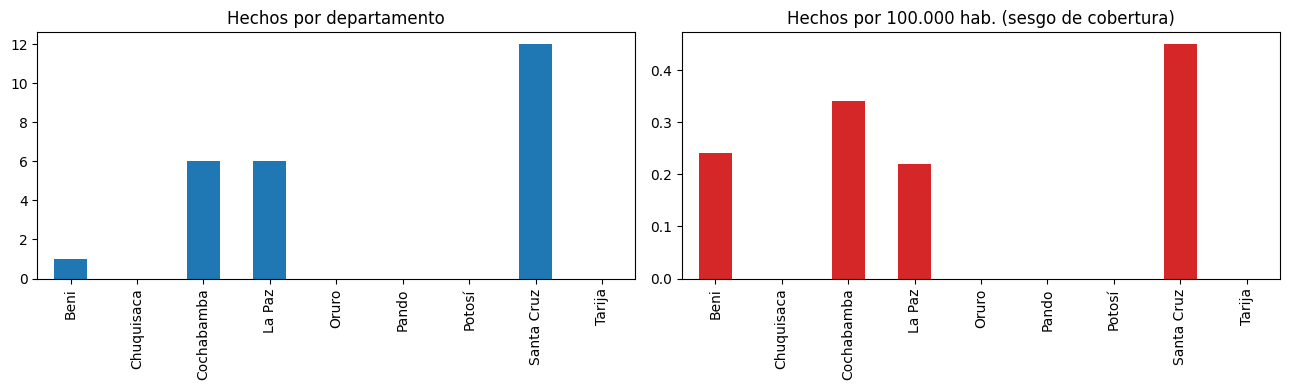

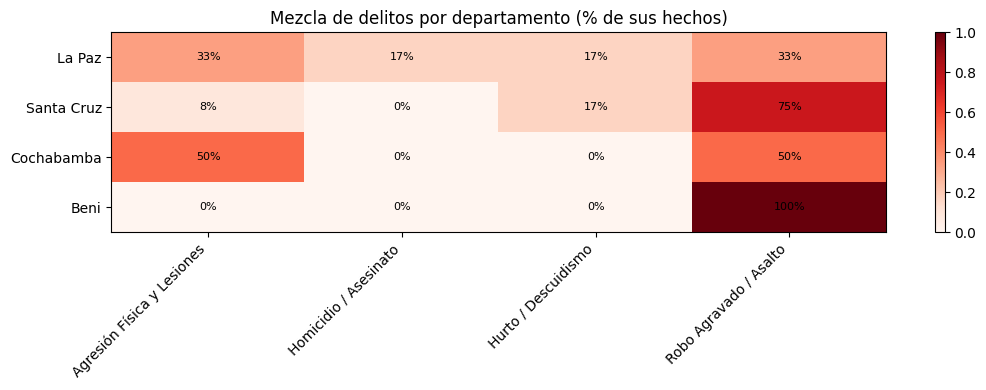

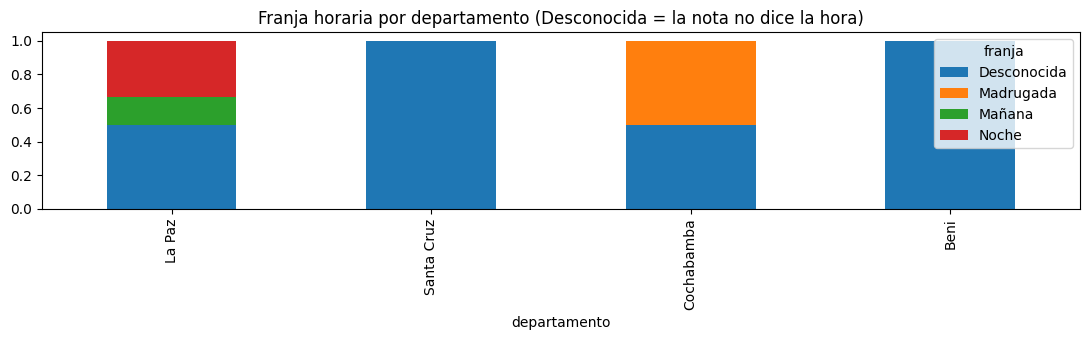

In [17]:
import matplotlib.pyplot as plt
import folium

def panorama_nacional(df):
    if df.empty: print("Sin datos todavía."); return
    n = df.groupby("departamento").size().reindex(list(DEPARTAMENTOS)).fillna(0).astype(int)
    res = pd.DataFrame({"hechos": n, "por_100k_hab": (n / pd.Series(POBLACION) * 1e5).round(2)})
    display(res)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    res["hechos"].plot.bar(ax=ax[0], title="Hechos por departamento"); res["por_100k_hab"].plot.bar(ax=ax[1], color="tab:red", title="Hechos por 100.000 hab. (sesgo de cobertura)")
    plt.tight_layout(); plt.show()
    ct = pd.crosstab(df.departamento, df.delito_principal, normalize="index").reindex(list(DEPARTAMENTOS)).dropna(how="all")
    fig, ax = plt.subplots(figsize=(11, 4)); im = ax.imshow(ct.to_numpy(), cmap="Reds", aspect="auto")
    ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=45, ha="right"); ax.set_yticks(range(ct.shape[0]), ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]): ax.text(j, i, f"{ct.iloc[i, j]:.0%}", ha="center", va="center", fontsize=8)
    ax.set_title("Mezcla de delitos por departamento (% de sus hechos)"); plt.colorbar(im); plt.tight_layout(); plt.show()
    fr = pd.crosstab(df.departamento, df.franja, normalize="index").reindex(list(DEPARTAMENTOS)).dropna(how="all")
    fr.plot.bar(stacked=True, figsize=(11, 3.5), title="Franja horaria por departamento (Desconocida = la nota no dice la hora)"); plt.tight_layout(); plt.show()

def mapa_nacional(df_ciu, df_zon):
    """Círculos por ciudad (tamaño = nº de hechos; ubicación = centro aproximado) y puntos de zona donde hay coordenadas."""
    m = folium.Map(location=[-16.7, -64.7], zoom_start=6)
    for c, n in df_ciu.ciudad.value_counts().items():
        _, la, lo, _ = CIUDADES[c]
        top = df_ciu[df_ciu.ciudad == c].delito_principal.value_counts().head(3).to_dict()
        folium.CircleMarker([la, lo], radius=4 + 2 * n ** 0.5, color="crimson", fill=True, fill_opacity=0.5, popup=f"{c}: {n} hechos | {top}").add_to(m)
    g = df_zon.groupby(["ciudad", "zona_principal", "lat", "lon"]).size().reset_index(name="n")
    for _, r in g.iterrows():
        folium.CircleMarker([r.lat, r.lon], radius=2 + r.n, color="navy", fill=True, popup=f"{r.zona_principal} ({r.ciudad}): {r.n}").add_to(m)
    return m

panorama_nacional(df_nac)
mapa_nacional(df_ciudad, df_zona)

## 12. Modelos no supervisados
Reglas de este bloque:
- Cada sección se **omite sola** si no hay suficientes datos (umbrales abajo) y te lo dice; no se fuerzan clusters con 10 puntos.
- Densidad espacial (DBSCAN/HDBSCAN/OPTICS) **ciudad por ciudad**, nunca mezclando ciudades.
- Mientras la coordenada sea el centro de la *zona*, todos los hechos de una zona caen en el mismo punto: la densidad solo distingue zonas vecinas. Para "puntos calientes" reales hace falta geocodificar a calle/esquina (columna `via_mencionada`). Dilo en el informe como limitación y trabajo futuro.

In [19]:
MIN_NACIONAL = 20         # hechos para el análisis de texto
MIN_DEPTO = 10             # hechos por departamento para compararlo
MIN_ZONA_CIUDAD = 30       # hechos con zona en una ciudad para densidad espacial
MIN_ZONAS_CLUSTER = 8      # zonas distintas para clusterizar zonas
if len(df_nac) < MIN_NACIONAL:
    raise RuntimeError(f"Solo hay {len(df_nac)} hechos con departamento (mínimo recomendado: {MIN_NACIONAL}). Mira el EMBUDO y amplía fuentes/sitemaps antes de modelar.")
print(f"OK: {len(df_nac)} hechos nacionales | ciudades con ≥{MIN_ZONA_CIUDAD} hechos con zona: {[c for c, n in df_zona.ciudad.value_counts().items() if n >= MIN_ZONA_CIUDAD]}")

OK: 25 hechos nacionales | ciudades con ≥30 hechos con zona: []


### 12.1 Departamentos: PCA → K-means / jerárquico
Cada departamento es un punto descrito por su mezcla de delitos, % nocturno, gravedad media y tasa por 100.000 hab. (log). Con 9 departamentos es **exploratorio**.

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN, OPTICS
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

def tabla_deptos(df, min_eventos=MIN_DEPTO):
    d = df.copy(); d["peso"] = d["delito_principal"].map(PESO).fillna(1)
    T = d.groupby("departamento").agg(n_hechos=("url", "size"), gravedad_media=("peso", "mean"),
                                      pct_nocturno=("franja", lambda s: s.isin(["Noche", "Madrugada"]).mean()))
    T = T.join(pd.crosstab(d["departamento"], d["delito_principal"], normalize="index").add_prefix("pct_"))
    T["log_tasa_100k"] = np.log1p(T["n_hechos"] / pd.Series(POBLACION).reindex(T.index) * 1e5)
    return T[T["n_hechos"] >= min_eventos]

def clusterizar(T, cols, nombre):
    Z = StandardScaler().fit_transform(T[cols])
    pca = PCA(n_components=min(5, Z.shape[1], Z.shape[0] - 1)).fit(Z); Zp = pca.transform(Z)
    print("Varianza explicada PCA:", pca.explained_variance_ratio_.round(2))
    ks = range(2, min(8, len(T)))
    sil = {k: silhouette_score(Zp, KMeans(k, n_init=10, random_state=0).fit_predict(Zp)) for k in ks}
    k = max(sil, key=sil.get); print("Silhouette por k:", {a: round(b, 3) for a, b in sil.items()}, "-> k =", k)
    T = T.copy(); T["kmeans"] = KMeans(k, n_init=10, random_state=0).fit_predict(Zp); T["jerarquico"] = AgglomerativeClustering(k, linkage="ward").fit_predict(Zp)
    plt.figure(figsize=(10, 4)); dendrogram(linkage(Zp, "ward"), labels=[str(i) for i in T.index], leaf_rotation=90); plt.title(f"Dendrograma: {nombre}"); plt.tight_layout(); plt.show()
    return T

TD = tabla_deptos(df_nac)
if len(TD) >= 4:
    TD = clusterizar(TD, [c for c in TD.columns if c != "n_hechos"], "departamentos"); display(TD.round(2))
else:
    print(f"Solo {len(TD)} departamentos con ≥{MIN_DEPTO} hechos: se necesitan al menos 4. Sección omitida.")

Solo 1 departamentos con ≥10 hechos: se necesitan al menos 4. Sección omitida.


### 12.2 Densidad espacial por ciudad: DBSCAN, HDBSCAN, OPTICS (haversine)

In [21]:
RT = 6371.0088
def clusters_espaciales(p, radio_m=600, min_pts=5):
    p = p.dropna(subset=["lat", "lon"]).copy()
    u = p.groupby(["lat", "lon"]).size().reset_index(name="n")      # DBSCAN sobre puntos únicos ponderados (evita degenerar con duplicados exactos)
    u["dbscan"] = DBSCAN(eps=radio_m / 1000 / RT, min_samples=min_pts, metric="haversine").fit(np.radians(u[["lat", "lon"]]), sample_weight=u["n"].to_numpy()).labels_
    p = p.merge(u[["lat", "lon", "dbscan"]], on=["lat", "lon"], how="left")
    X = np.radians(p[["lat", "lon"]].to_numpy())
    p["hdbscan"] = HDBSCAN(min_cluster_size=min_pts, metric="haversine").fit_predict(X)
    p["optics"] = OPTICS(min_samples=min_pts, metric="haversine", xi=0.05).fit_predict(X)
    return p

resultados_espaciales = {}
for ciudad, n in df_zona.ciudad.value_counts().items():
    if n < MIN_ZONA_CIUDAD:
        print(f"{ciudad}: {n} hechos con zona (< {MIN_ZONA_CIUDAD}) -> se omite"); continue
    esp = clusters_espaciales(df_zona[df_zona.ciudad == ciudad]); resultados_espaciales[ciudad] = esp
    print(f"\n{ciudad} ({len(esp)} hechos, {esp[['lat', 'lon']].drop_duplicates().shape[0]} puntos distintos)")
    for c in ["dbscan", "hdbscan", "optics"]:
        print(f"  {c:8s} clusters={len(set(esp[c])) - (1 if -1 in set(esp[c]) else 0)}  ruido={(esp[c] == -1).sum()}")
    plt.figure(figsize=(5, 4)); plt.scatter(esp.lon, esp.lat, c=esp["dbscan"], cmap="tab10", s=12 + 4 * esp.groupby(["lat", "lon"])["url"].transform("size")); plt.title(f"{ciudad}: DBSCAN"); plt.show()
if not resultados_espaciales: print("\nNingua ciudad llega al mínimo: sección omitida. Agrega zonas (NUEVAS_ZONAS / gazetteer) y fuentes.")

La Paz: 2 hechos con zona (< 30) -> se omite

Ningua ciudad llega al mínimo: sección omitida. Agrega zonas (NUEVAS_ZONAS / gazetteer) y fuentes.


### 12.3 Zonas: PCA → K-means / jerárquico (todas las ciudades juntas, cada zona con su ciudad)

In [22]:
def tabla_zonas(df, min_eventos=2):
    d = df.copy(); d["peso"] = d["delito_principal"].map(PESO).fillna(1)
    g = d.groupby(["ciudad", "zona_principal"])
    T = g.agg(n_hechos=("url", "size"), indice_gravedad=("peso", "sum"), pct_nocturno=("franja", lambda s: s.isin(["Noche", "Madrugada"]).mean()), lat=("lat", "first"), lon=("lon", "first"))
    T = T.join(pd.crosstab([d["ciudad"], d["zona_principal"]], d["delito_principal"], normalize="index").add_prefix("pct_"))
    T.index = [f"{z} ({c})" for c, z in T.index]
    return T[T.n_hechos >= min_eventos]

TZ = tabla_zonas(df_zona)
if len(TZ) >= MIN_ZONAS_CLUSTER:
    TZ = clusterizar(TZ, [c for c in TZ.columns if c not in ("lat", "lon")], "zonas"); display(TZ.sort_values("indice_gravedad", ascending=False).round(2))
else:
    print(f"Solo {len(TZ)} zonas con ≥2 hechos (se necesitan {MIN_ZONAS_CLUSTER}). Sección omitida.")

Solo 0 zonas con ≥2 hechos (se necesitan 8). Sección omitida.


### 12.4 Texto: LDA, SVD, t-SNE y UMAP (todas las notas con departamento)

Tema 0: vecinos, hecho, llevaron, robo, delincuentes, autoridades, victima, jovenes, seguridad, dinero
Tema 1: incluso, hecho, vehiculo, vecinos, lugar, hechos, ocurrio, otros, victimas, robo
Tema 2: vehiculo, repartidores, cuatro, objetos, aproximadamente, pertenencias, parte, explico, delincuentes, lugar
Tema 3: delincuentes, victima, mientras, hecho, arma, antisociales, joven, dentro, denuncia, mochila
Tema 4: victima, arma, victimas, penal, camaras, momento, atraco, tres, hecho, ocurrido
tema_lda      0  1  2  3  4
departamento               
Beni          0  0  0  1  0
Cochabamba    2  1  1  0  2
La Paz        2  1  0  2  1
Santa Cruz    4  1  3  3  1


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


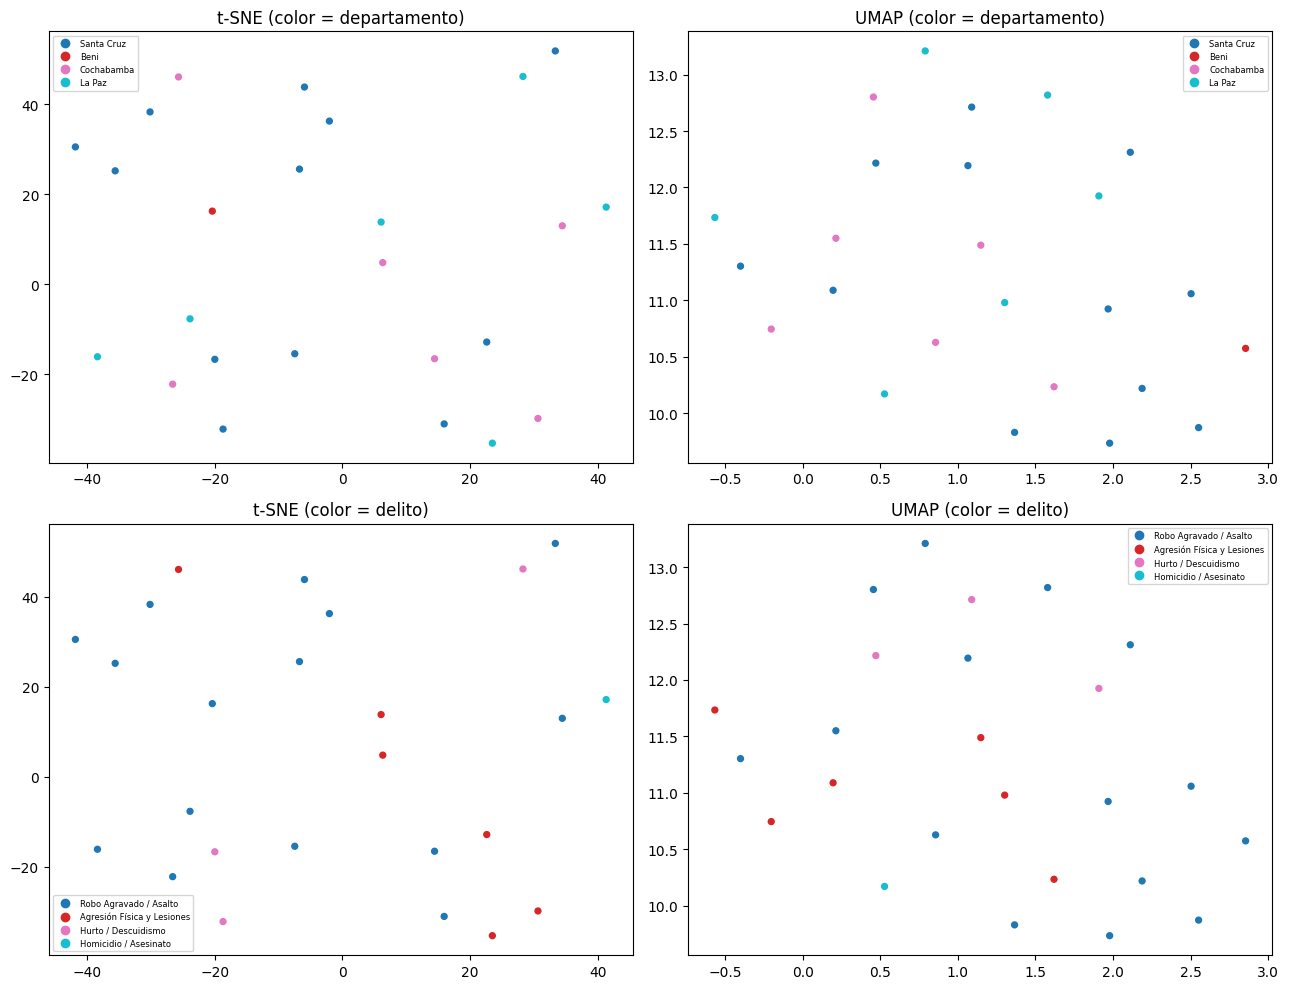

In [23]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.manifold import TSNE
import umap

STOP_ES = set("""a al algo ante asi aun aunque bajo cada como con contra cual cuando de del desde donde dos el ella ellos en entre era eran es esa ese eso esta estaba estan este esto estos fue fueron ha habia han hasta hay la las le les lo los mas me mi muy ni no nos o otra otro para pero por porque que quien se sea segun ser si sin sobre son su sus tambien tras un una uno unos y ya
paz alto bolivia policia policial policias fue sido tras dijo indico informo senalo ayer hoy anos ano horas hora zona santa cruz cochabamba sucre oruro potosi tarija trinidad cobija""".split())

def vectorizar(textos, tfidf=False):
    V = (TfidfVectorizer if tfidf else CountVectorizer)(strip_accents="unicode", lowercase=True, stop_words=list(STOP_ES), max_df=0.8, min_df=2, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    return V.fit_transform(textos), V

dfc = df_nac.copy().reset_index(drop=True)
Xc, Vc = vectorizar(dfc["texto"]); n_temas = 5
lda = LatentDirichletAllocation(n_components=n_temas, random_state=0, learning_method="batch").fit(Xc)
vocab = np.array(Vc.get_feature_names_out())
for t, comp in enumerate(lda.components_): print(f"Tema {t}:", ", ".join(vocab[comp.argsort()[-10:][::-1]]))
dfc["tema_lda"] = lda.transform(Xc).argmax(axis=1)
print(pd.crosstab(dfc["departamento"], dfc["tema_lda"]))

Xt, Vt = vectorizar(dfc["texto"], tfidf=True)
Xs = TruncatedSVD(n_components=min(30, Xt.shape[1] - 1), random_state=0).fit_transform(Xt)
tsne = TSNE(2, perplexity=max(5, min(30, len(dfc) // 4)), random_state=0, init="pca").fit_transform(Xs)
um = umap.UMAP(n_components=2, n_neighbors=min(15, len(dfc) - 1), random_state=0).fit_transform(Xs)
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for j, (col, tit) in enumerate([("departamento", "departamento"), ("delito_principal", "delito")]):
    codigos, etiquetas = pd.factorize(dfc[col])
    for i, (E, nom) in enumerate([(tsne, "t-SNE"), (um, "UMAP")]):
        sc = ax[j, i].scatter(E[:, 0], E[:, 1], c=codigos, cmap="tab10", s=18); ax[j, i].set_title(f"{nom} (color = {tit})")
        ax[j, i].legend(handles=sc.legend_elements()[0], labels=list(etiquetas), fontsize=6, loc="best")
plt.tight_layout(); plt.show()

## 13. Exportar para el dashboard
Genera CSV y un JSON **sin el texto de las notas ni los títulos** (pueden traer nombres de víctimas): solo ubicación, delito, franja, fecha y enlace a la fuente.

In [24]:
def exportar_resultados():
    os.makedirs(CARPETA_SALIDA, exist_ok=True)
    cols = ["fecha", "fuente", "url", "departamento", "ciudad", "zona_principal", "nivel_geo", "lat", "lon", "delito_principal", "franja", "dia_semana"]
    df_nac[cols].to_csv(f"{CARPETA_SALIDA}/eventos_limpios.csv", index=False, encoding="utf-8")
    df_nac.groupby(["departamento", "delito_principal"]).size().reset_index(name="hechos").to_csv(f"{CARPETA_SALIDA}/resumen_departamento.csv", index=False)
    df_ciudad.groupby(["departamento", "ciudad", "delito_principal"]).size().reset_index(name="hechos").to_csv(f"{CARPETA_SALIDA}/resumen_ciudad.csv", index=False)
    zonas = df_zona.groupby(["departamento", "ciudad", "zona_principal", "lat", "lon", "delito_principal"]).size().reset_index(name="hechos")
    zonas.to_csv(f"{CARPETA_SALIDA}/resumen_zona.csv", index=False)
    datos = {"departamentos": json.loads(df_nac.groupby("departamento").size().to_json()),
             "ciudades": [{"ciudad": c, "departamento": CIUDADES[c][0], "lat": CIUDADES[c][1], "lon": CIUDADES[c][2], "hechos": int(n)} for c, n in df_ciudad.ciudad.value_counts().items()],
             "zonas": json.loads(zonas.to_json(orient="records", force_ascii=False))}
    json.dump(datos, open(f"{CARPETA_SALIDA}/dashboard_data.json", "w"), ensure_ascii=False, indent=1)
    print("Exportado en", CARPETA_SALIDA, "->", os.listdir(CARPETA_SALIDA))

exportar_resultados()

Exportado en salida -> ['resumen_ciudad.csv', 'resumen_departamento.csv', 'resumen_zona.csv', 'dashboard_data.json', 'eventos_limpios.csv']


## Pendiente (siguiente fase)
- **Autoencoder** (Keras) sobre TF-IDF/SVD y **PPCA** para comparar con PCA.
- Geocodificación a nivel calle/esquina (`via_mencionada`) o extracción de ubicación con un LLM, para densidad real dentro de cada zona.
- Medios locales de **Beni y Pando**, y más meses de datos por departamento.
- Datos oficiales (Policía, Observatorio, municipios) para **validar** lo que muestran las noticias; y Censo 2024 en `POBLACION`.
- Validar todo el pipeline con los datos de Chicago antes de interpretar resultados de Bolivia.